# 00 - Download and explore one MARCO TFRecord shard

Goal: confirm we can download a shard from marco.ccr.buffalo.edu and read it with the pure-Python
`tfrecord` package (no TensorFlow needed), before writing the full `scripts/download_extract.py`.

This only touches **one** shard (~123MB) so it stays fast to re-run.

In [1]:
import urllib.request
from pathlib import Path

import pandas as pd
from PIL import Image
from tfrecord.reader import tfrecord_loader

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
SAMPLE_DIR = PROJECT_ROOT / "data" / "sample"
RAW_DIR.mkdir(parents=True, exist_ok=True)

SHARD_URL = "https://marco.ccr.buffalo.edu/data/train-jpg/train-00001-of-00407"
SHARD_PATH = RAW_DIR / "train-00001-of-00407"

In [2]:
if not SHARD_PATH.exists():
    urllib.request.urlretrieve(SHARD_URL, SHARD_PATH)

print(SHARD_PATH, SHARD_PATH.stat().st_size / 1e6, "MB")

/Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/raw/train-00001-of-00407 123.083758 MB


In [3]:
# Inspect one raw record first - the MARCO docs describe the field names but not exactly how
# the `tfrecord` package returns each field's Python type, so check empirically rather than assume.
probe_loader = tfrecord_loader(str(SHARD_PATH), None)
probe_record = next(iter(probe_loader))
for key, value in probe_record.items():
    print(key, type(value), value if isinstance(value, bytes) and len(value) < 50 else "")

image/class/label <class 'numpy.ndarray'> 
image/format <class 'bytes'> b'JPEG'
image/class/source <class 'numpy.ndarray'> 
image/width <class 'numpy.ndarray'> 
image/id <class 'numpy.ndarray'> 
image/filename <class 'bytes'> b'X0000039760279200409281034.png'
image/channels <class 'numpy.ndarray'> 
image/class/raw <class 'numpy.ndarray'> 
image/height <class 'numpy.ndarray'> 
image/encoded <class 'bytes'> 
image/class/text <class 'bytes'> b'Clear'
image/colorspace <class 'bytes'> b'RGB'


In [4]:
# The TFRecord schema (verified empirically - see the field-type probe above):
#   image/encoded      bytes (not list-wrapped) - JPEG bytes
#   image/class/text    bytes (not list-wrapped) - human-readable label
#   image/class/source  numpy array of int - source institution id
#   image/filename      bytes (not list-wrapped)
#   image/id            numpy array of int
loader = tfrecord_loader(str(SHARD_PATH), None)

records = []
for i, record in enumerate(loader):
    records.append(
        {
            "filename": record["image/filename"].decode("utf-8"),
            "id": int(record["image/id"][0]),
            "label": record["image/class/text"].decode("utf-8"),
            "source": int(record["image/class/source"][0]),
            "n_bytes": len(record["image/encoded"]),
        }
    )
    if i >= 999:  # just the first ~1000 records of this shard for a quick look
        break

df = pd.DataFrame(records)
print(df.shape)
df.head()

(1000, 5)


,filename,id,label,source,n_bytes
0,X0000039760279200409281034.png,396612,Clear,2,20706
1,folderID125_plateID3125_batchID18048_wellNum22...,286612,Precipitate,3,120311
2,X0000042171126200411151543.png,421709,Precipitate,2,26594
3,folderID281_plateID1281_batchID4174_wellNum16_...,90089,Clear,3,112353
4,folderID511_plateID3511_batchID20741_wellNum58...,296118,Precipitate,3,136738


In [5]:
df["label"].value_counts()

label
Precipitate    500
Clear          320
Crystals       119
Other           61
Name: count, dtype: int64

In [6]:
df["source"].value_counts()

source
3    632
2    169
1    159
0     30
4     10
Name: count, dtype: int64

In [7]:
# look at filenames - checking whether they hint at plate/well grouping for the leakage check
df["filename"].head(20).tolist()

['X0000039760279200409281034.png',
 'folderID125_plateID3125_batchID18048_wellNum22_profileID1_d1_r267583_ef.jpg',
 'X0000042171126200411151543.png',
 'folderID281_plateID1281_batchID4174_wellNum16_profileID1_d2_r75863_ef.jpg',
 'folderID511_plateID3511_batchID20741_wellNum58_profileID1_d1_r315192_ef.jpg',
 '06d7_E4_CrossPolarization_9.jpg',
 'folderID647_plateID2647_batchID13388_wellNum72_profileID1_d2_r213829_ef.jpg',
 'folderID987_plateID987_batchID1639_wellNum74_profileID1_d2_r40461_ef.jpg',
 '06hl_A5_ImagerDefaults_0.jpg',
 'folderID440_plateID1440_batchID5495_wellNum68_profileID1_d1_r90498_ef.jpg',
 'X0000043780431200412291330.png',
 '046p_H9_ImagerDefaults_2.jpg',
 'folderID828_plateID1828_batchID8015_wellNum89_profileID1_d2_r122259_ef.jpg',
 'folderID241_plateID3241_batchID19740_wellNum90_profileID1_d2_r284022_ef.jpg',
 'folderID505_plateID1505_batchID5837_wellNum26_profileID1_d1_r95274_ef.jpg',
 'folderID242_plateID3242_batchID19196_wellNum13_profileID1_d2_r282524_ef.jpg',
 'f

In [8]:
# save one decoded image per class we've seen, into data/sample/<class>/, as an end-to-end check
loader = tfrecord_loader(str(SHARD_PATH), None)
saved_labels = set()

for record in loader:
    label = record["image/class/text"].decode("utf-8")
    if label in saved_labels:
        continue
    out_dir = SAMPLE_DIR / label
    out_dir.mkdir(parents=True, exist_ok=True)
    filename = record["image/filename"].decode("utf-8")
    jpeg_bytes = record["image/encoded"]
    (out_dir / filename).write_bytes(jpeg_bytes)
    saved_labels.add(label)
    print("saved", out_dir / filename)
    if len(saved_labels) >= 4:
        break

saved /Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Clear/X0000039760279200409281034.png
saved /Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Precipitate/folderID125_plateID3125_batchID18048_wellNum22_profileID1_d1_r267583_ef.jpg
saved /Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Crystals/06d7_E4_CrossPolarization_9.jpg
saved /Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Other/X0000041230471200411182048.png


In [9]:
# visually confirm one of the saved images decodes correctly
sample_files = list(SAMPLE_DIR.glob("*/*"))
sample_files

[PosixPath('/Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Other/X0000041230471200411182048.png'),
 PosixPath('/Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Clear/X0000039760279200409281034.png'),
 PosixPath('/Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Crystals/06d7_E4_CrossPolarization_9.jpg'),
 PosixPath('/Users/chamika/Documents/MSc_Data_Science/AI/AI_project/data/sample/Precipitate/folderID125_plateID3125_batchID18048_wellNum22_profileID1_d1_r267583_ef.jpg')]

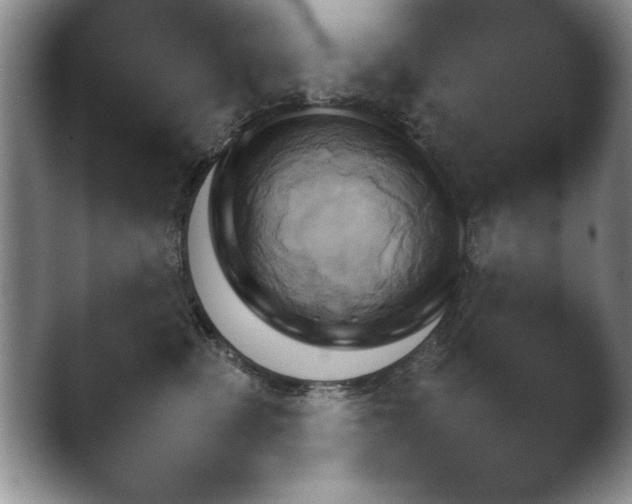

In [10]:
Image.open(sample_files[0])    # 0 → Other (X0000041230471200411182048.png)

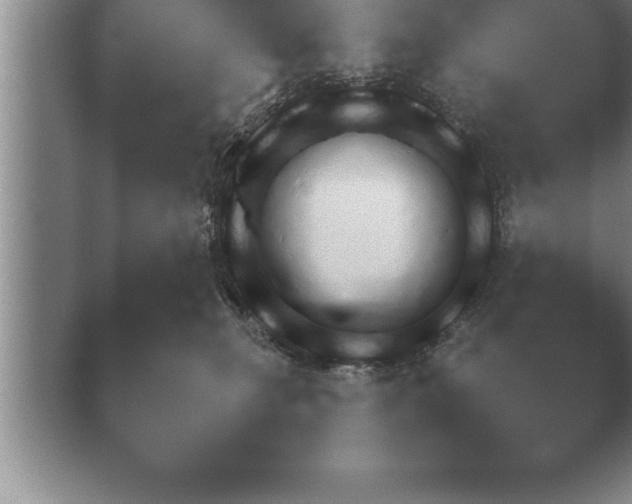

In [11]:
Image.open(sample_files[1])   # 1 → Clear (X0000039760279200409281034.png)

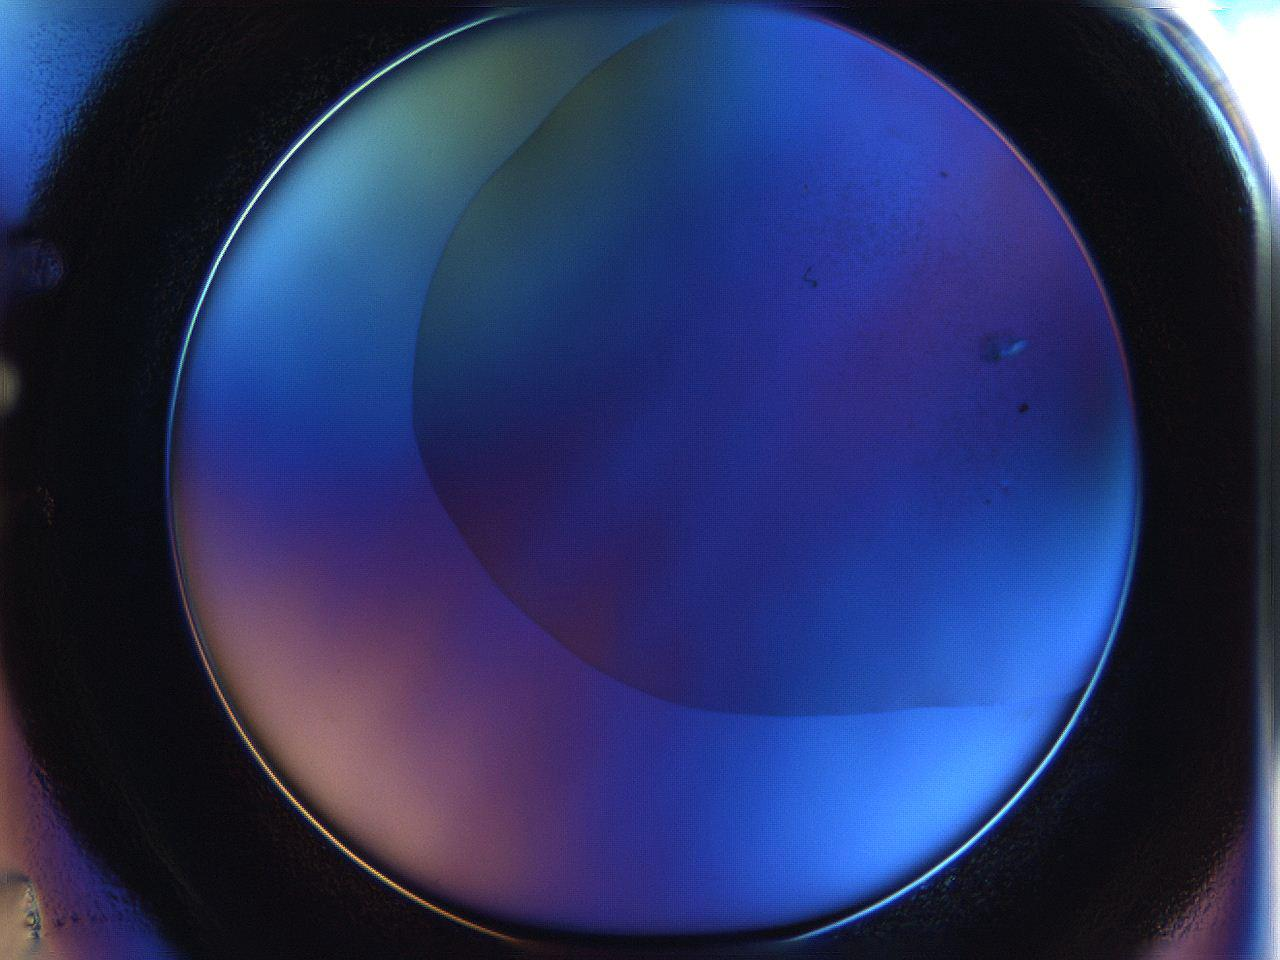

In [12]:
Image.open(sample_files[2])   # 2 → Crystals (06d7_E4_CrossPolarization_9.jpg)

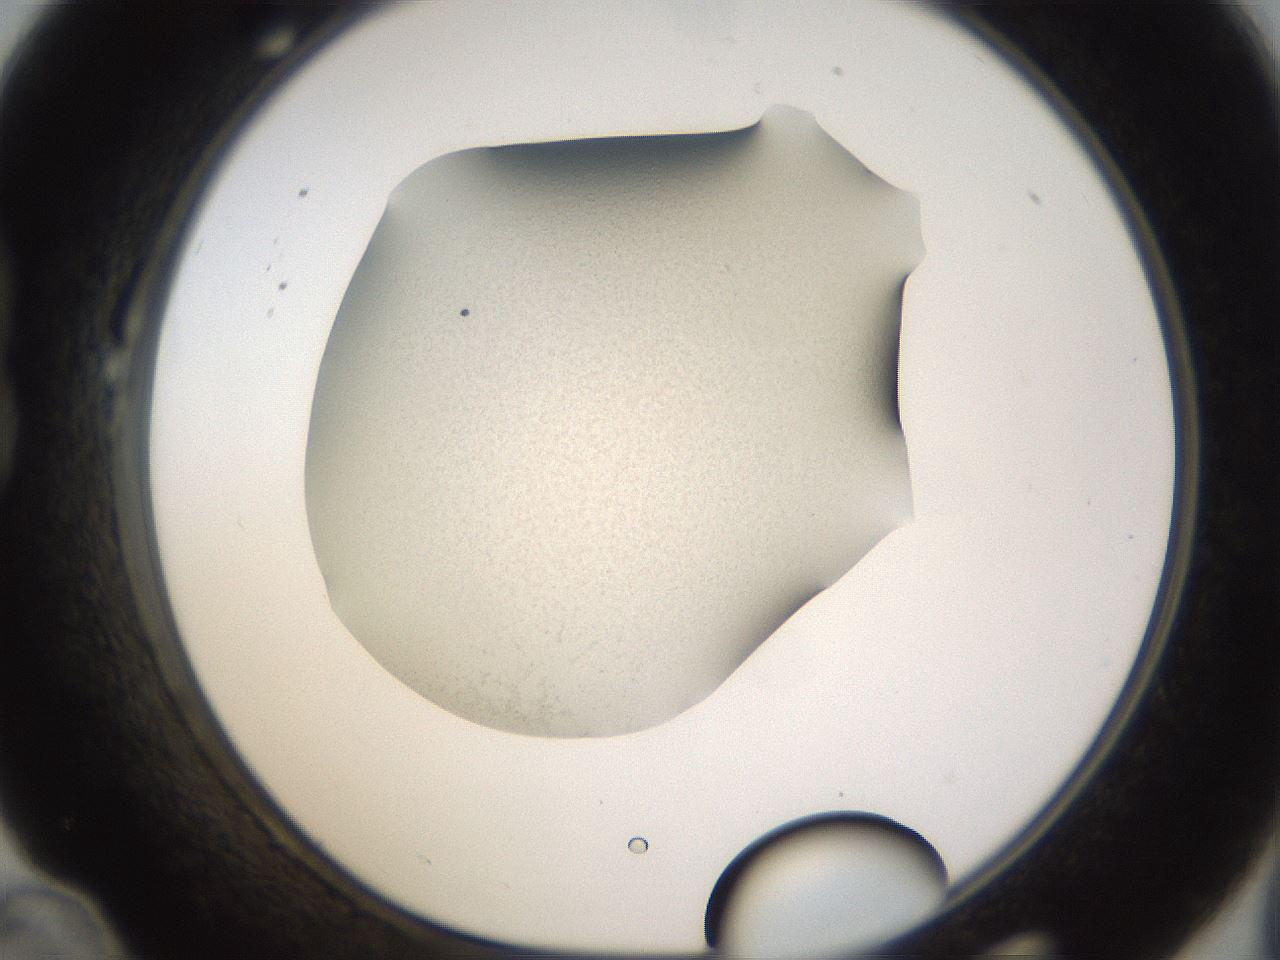

In [13]:
Image.open(sample_files[3])     # 3 → Precipitate (folderID125_plateID3125_batchID18048_wellNum22_..._ef.jpg)

## One example image per class

A single combined figure, for the report - what each class actually looks like, side by side,
before diving into the distribution statistics.

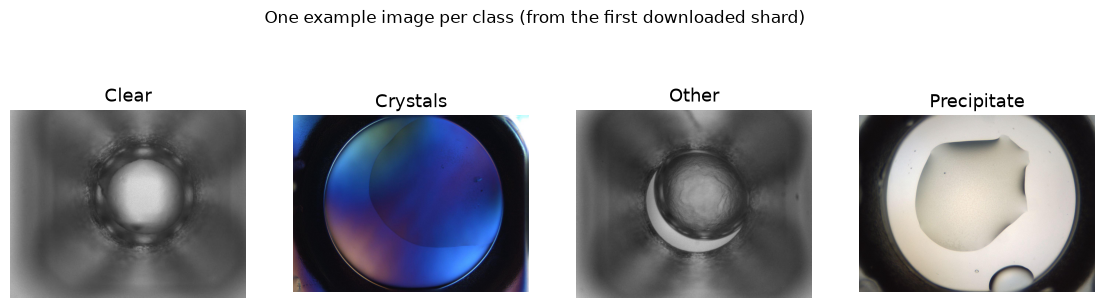

In [14]:
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = ["Clear", "Crystals", "Other", "Precipitate"]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, cls in zip(axes, CLASS_ORDER):
    img_path = next((SAMPLE_DIR / cls).glob("*"))
    ax.imshow(Image.open(img_path))
    ax.set_title(cls, fontsize=13)
    ax.axis("off")
fig.suptitle("One example image per class (from the first downloaded shard)", fontsize=12)
fig.savefig(FIGURES_DIR / "q1_example_images_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

## Is class balance stable across shards?

Shard 1 (first ~1000 records) showed Precipitate 500 / Clear 320 / Crystals 119 / Other 61.
Before deciding how many shards to pull for the working dataset, check whether this ratio holds
on two more shards spread across the file range (100 and 300 of 407) - if MARCO shuffled before
sharding, proportions should be similar; if not, we'd need to pull more shards than planned to
get a stable sample.

In [15]:
SHARD_IDS = [100, 300]
shard_paths = {}
for sid in SHARD_IDS:
    name = f"train-{sid:05d}-of-00407"
    url = f"https://marco.ccr.buffalo.edu/data/train-jpg/{name}"
    path = RAW_DIR / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    shard_paths[sid] = path
    print(name, round(path.stat().st_size / 1e6, 1), "MB")

train-00100-of-00407 131.4 MB
train-00300-of-00407 131.7 MB


In [16]:
def shard_labels(path):
    loader = tfrecord_loader(str(path), None)
    return pd.Series([r["image/class/text"].decode("utf-8") for r in loader])

label_series = {1: shard_labels(SHARD_PATH)}
for sid, path in shard_paths.items():
    label_series[sid] = shard_labels(path)

shard_sizes = {sid: len(s) for sid, s in label_series.items()}
print("records per shard:", shard_sizes)

counts_df = pd.DataFrame({sid: s.value_counts() for sid, s in label_series.items()}).fillna(0).astype(int)
counts_df

records per shard: {1: 1024, 100: 1024, 300: 1024}


,1,100,300
Precipitate,512,497,504
Clear,329,348,302
Crystals,121,135,152
Other,62,44,66


In [17]:
# percentage breakdown per shard, for easy comparison
(counts_df / counts_df.sum(axis=0) * 100).round(1)

,1,100,300
Precipitate,50.0,48.5,49.2
Clear,32.1,34.0,29.5
Crystals,11.8,13.2,14.8
Other,6.1,4.3,6.4


## Full dataset reference distribution

For comparison: the published MARCO `train` split's label distribution across all 407 shards
(marco.ccr.buffalo.edu) - this is what `docs/report.md` means when it says the 15-shard
sample's ~12.4% Crystals share is "consistent with the ~13% figure reported for the published
MARCO training set."

In [18]:
full_train_counts = pd.Series({
    "Precipitate": 199567,
    "Clear": 139865,
    "Crystals": 53044,
    "Other": 23299,
})
full_train_pct = (full_train_counts / full_train_counts.sum() * 100).round(1)
print(f"total: {full_train_counts.sum()}")
pd.DataFrame({"Count": full_train_counts, "%": full_train_pct})

total: 415775


,Count,%
Precipitate,199567,48.0
Clear,139865,33.6
Crystals,53044,12.8
Other,23299,5.6


## Statistical test: is each sampled shard consistent with the full population?

The percentage table above suggests the three shards (1, 100, 300) look similar to each other
and to the full-population reference - but that's an eyeballed comparison. Test it properly: a
chi-square goodness-of-fit test of each shard's observed label counts against the full
population's proportions, scaled to that shard's size.

In [19]:
from scipy.stats import chisquare

expected_props = full_train_counts.reindex(counts_df.index) / full_train_counts.sum()

rows = []
for shard_id in counts_df.columns:
    observed = counts_df[shard_id]
    expected = expected_props * observed.sum()
    chi2_stat, p_value = chisquare(f_obs=observed.values, f_exp=expected.values)
    rows.append({"shard": str(shard_id), "n": int(observed.sum()), "chi2": chi2_stat, "p_value": p_value})

# Pooled: sum counts across all 3 shards first, then test once - not the same as averaging the
# three p-values, and the statistically correct way to combine evidence from multiple samples
# into one test (chi-square needs counts, not already-normalised percentages).
pooled_observed = counts_df.sum(axis=1)
pooled_expected = expected_props * pooled_observed.sum()
pooled_chi2, pooled_p = chisquare(f_obs=pooled_observed.values, f_exp=pooled_expected.values)
rows.append({"shard": "combined (1+100+300)", "n": int(pooled_observed.sum()),
             "chi2": pooled_chi2, "p_value": pooled_p})

chi2_per_shard = pd.DataFrame(rows).set_index("shard")
chi2_per_shard["chi2"] = chi2_per_shard["chi2"].round(3)
chi2_per_shard["p_value"] = chi2_per_shard["p_value"].round(4)
chi2_per_shard

,n,chi2,p_value
shard,,,
1,1024,2.632,0.4519
100,1024,3.364,0.3388
300,1024,10.340,0.0159
combined (1+100+300),3072,4.528,0.2098


**Reading this honestly - not a clean result.** Shards 1 and 100 are statistically consistent
with the full population (p=0.452, p=0.339 - both well above 0.05). Shard 300 is not: p=0.016,
below the conventional 0.05 threshold, driven mainly by Crystals being overrepresented there
(14.8% vs. the population's 12.8%). This doesn't mean MARCO's sharding is biased - with 3
independent tests at α=0.05, there's roughly a 1-(0.95)³≈14% chance of at least one false
positive even if every shard were perfectly representative, and a single shard (n=1,024) is a
much noisier sample than an aggregate.

**Pooling the 3 shards confirms this directly.** Summing all three shards' counts first
(n=3,072) and testing once gives chi2=4.528, p=0.210 - not significant, even though one of the
three shards individually was. This is the statistically correct way to combine evidence across
samples (chi-square needs raw counts, not an average of three separate p-values or percentages),
and it shows concretely that shard 300's single-shard deviation is noise that washes out once
pooled, not a sign of real sharding bias. It's consistent with the larger **15-shard aggregate
test in `notebooks/01_eda.ipynb`** (n=12,314, chi2=2.53, p=0.470, also not significant) - pooling
enough shards is exactly what smooths out this kind of single-shard noise, which is the reason
15 shards were pulled for the working dataset rather than relying on just one or two.

## Summary

| Shard | n | chi2 | p-value |
|---|---|---|---|
| 1 | 1,024 | 2.632 | 0.452 |
| 100 | 1,024 | 3.364 | 0.339 |
| 300 | 1,024 | 10.340 | 0.016 |
| combined (1+100+300) | 3,072 | 4.528 | 0.210 |

Pooling confirms the earlier concern directly: shard 300's individual significance washes out
once combined with the other two - not significant (p=0.210). This is the statistically correct
way to combine evidence (summing counts first, then testing once - not averaging the three
p-values, which wouldn't be valid). It lines up with the larger 15-shard aggregate test in
`01_eda.ipynb` (p=0.470), reinforcing why pooling multiple shards rather than relying on any
single one was the right call for this project's working dataset.